# 04c · Econometric hedonic model: implicit prices, diagnostics, spatial dependence and new MRT stations
**Owner:** Pricing & Availability Lead · **Needs:** steps 1b–6; `pyfixest`, `spreg`, `libpysal`, `esda` · Companion to notebooks 04 and 04b

Notebooks 04 and 04b build and validate the production model (LightGBM). This notebook is its econometric counterpart, in the
tradition of Rosen (1974): a regression whose coefficients are implicit prices, with the diagnostics a hedonic study needs.

| § | Question | Method |
|---|---|---|
| 1 | What is each attribute worth, in % and in dollars? Do the two models agree? | Semi-log regression with town and month fixed effects, block-clustered standard errors; compared with LightGBM marginal effects |
| 2 | Is the specification right? | Multicollinearity (VIF), heteroskedasticity (Breusch–Pagan), functional form (Box–Cox, RESET), influence (Cook's distance), error tails |
| 3 | What happens when space is ignored? | Block-level model: Moran's I, Lagrange-multiplier tests, spatial-error and spatial-lag models |
| 4 | What does a new MRT station do to nearby prices? | Difference-in-differences and event study on stations opened 2019–2024 |

In [1]:
import sys, time, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import config as C
from homefit import common as K, hedonic as H
import pyfixest as pf, statsmodels.api as sm
from scipy import stats
BLUE, GREY, ORANGE, GREEN = "#2a78d6", "#9a9a95", "#eb6834", "#1baf7a"
plt.rcParams.update({"figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.edgecolor": "#9a9a95", "lines.linewidth": 1.8, "legend.frameon": False, "font.size": 10})
AS_OF = K.latest_complete_month()
d = H.training_frame(AS_OF).reset_index(drop=True)
d["lp"] = np.log(d["resale_price"]); d["log_area"] = np.log(d["floor_area_sqm"])
DIST = ["mrt", "hawker", "park", "supermarket", "polyclinic", "primary"]
for c in DIST: d["log_" + c] = np.log(d[f"dist_{c}_m"].clip(lower=50))
L = d["remaining_lease_yrs"]
for k in [60, 70, 80, 90]: d[f"lease_gt{k}"] = (L - k).clip(lower=0)
SPL = ["remaining_lease_yrs", "lease_gt60", "lease_gt70", "lease_gt80", "lease_gt90"]
CONT = ["log_area"] + SPL + ["storey_mid", "max_floor_lvl"] + ["log_" + c for c in DIST] + ["n_primary_1km", "n_preschool_500m", "n_chas_500m", "n_supermarket_500m"]
RHS = " + ".join(CONT) + " + C(flat_type) + C(flat_model_group)"
print(f"As of {AS_OF}: {len(d):,} sales, {d['address'].nunique():,} blocks, {d['month'].nunique()} months")

As of 2026-09: 241,273 sales, 9,711 blocks, 117 months


## 1 · The econometric hedonic model
$$\ln P_{ibt} = \beta_1 \ln \text{area}_i + g(\text{lease}_{it}) + \beta_2\,\text{storey}_i + \textstyle\sum_k \gamma_k \ln \text{dist}_{kb} + \delta' \text{counts}_b + \text{flat type} + \text{flat model} + \alpha_{\text{town}} + \tau_t + \varepsilon_{ibt}$$

- **Lease** enters as a linear spline with knots at 60, 70, 80 and 90 years, so the discount can steepen for short leases.
- **Distances** are in logs: a coefficient is the % change in price for a 1% change in distance (an elasticity).
- **Fixed effects** for the 26 towns and 117 months absorb town-wide location value and the market cycle.
- **Standard errors** are clustered by block: flats in a block share unobserved quality (condition, views, noise), so their errors are correlated.

MRT distance is the network **at the time of sale**, as in the production model.

In [2]:
t1 = time.time()
fit = {v: pf.feols(f"lp ~ {RHS} | town + month", data=d, vcov=v) for v in ["iid", "hetero"]}
fit["cluster"] = ols = pf.feols(f"lp ~ {RHS} | town + month", data=d, vcov={"CRV1": "address"})
print(f"3 fits in {time.time() - t1:.0f}s · R² {ols._r2:.3f} · within-R² {ols._r2_within:.3f} · RMSE (log) {np.sqrt(np.mean(ols.resid() ** 2)):.4f}")
T = ols.tidy()
se = pd.DataFrame({k: v.tidy()["Std. Error"] for k, v in fit.items()})
se["cluster / iid"] = se["cluster"] / se["iid"]
show = CONT + [c for c in T.index if c.startswith("C(flat_type)")]
print(T.loc[show, ["Estimate", "Std. Error", "2.5%", "97.5%", "Pr(>|t|)"]].round(5).to_string())
print("\nClustered SE / naive SE: median", round(se["cluster / iid"].median(), 2), "range", round(se["cluster / iid"].min(), 2), "–", round(se["cluster / iid"].max(), 2))
print("Clustered SE / heteroskedasticity-robust SE: median", round((se["cluster"] / se["hetero"]).median(), 2))
del fit                                           # free memory: only the clustered fit is kept

3 fits in 5s · R² 0.945 · within-R² 0.922 · RMSE (log) 0.0822
                           Estimate  Std. Error     2.5%    97.5%  Pr(>|t|)
Coefficient                                                                
log_area                    0.74645     0.01344  0.72011  0.77279   0.00000
remaining_lease_yrs         0.02074     0.00058  0.01961  0.02187   0.00000
lease_gt60                 -0.01433     0.00067 -0.01565 -0.01302   0.00000
lease_gt70                 -0.00215     0.00043 -0.00299 -0.00130   0.00000
lease_gt80                  0.00961     0.00053  0.00858  0.01065   0.00000
lease_gt90                 -0.00128     0.00073 -0.00270  0.00015   0.07848
storey_mid                  0.00672     0.00006  0.00660  0.00683   0.00000
max_floor_lvl               0.00254     0.00021  0.00214  0.00294   0.00000
log_mrt                    -0.07126     0.00154 -0.07428 -0.06823   0.00000
log_hawker                 -0.00828     0.00128 -0.01079 -0.00577   0.00000
log_park                  

**Implicit prices.** Rosen's first stage gives each attribute's marginal price, ∂P/∂x. In a semi-log model it depends on the price level,
so it is evaluated at the median resale price of the last 12 months. The same quantities are computed from the production LightGBM
model as **average marginal effects** (change each flat's attribute, re-predict, average the % change) on 5,000 recent sales.

In [3]:
b = T["Estimate"]; V = ols._vcov; names = list(T.index)
recent = d[d["t"] > K.month_index(AS_OF) - 12]; P0 = recent["resale_price"].median()
smp = recent.sample(5000, random_state=1).copy()
def lin(w):                                     # linear combination of coefficients: estimate and 95% CI
    w = pd.Series(w).reindex(names, fill_value=0).to_numpy(); e = w @ b.to_numpy(); s = np.sqrt(w @ V @ w)
    return e, e - 1.96 * s, e + 1.96 * s
def lease_slope(Lv):
    return {"remaining_lease_yrs": 1, **{f"lease_gt{k}": float(Lv > k) for k in [60, 70, 80, 90]}}
booster = lgb.Booster(model_file=str(C.PROCESSED / "hedonic_model.txt"))
cats = {c: pd.Categorical(d[c]).categories for c in H.CAT}
def gbm(df):
    Xd = df[H.FEATURES].copy()
    for c in H.CAT: Xd[c] = pd.Categorical(Xd[c], categories=cats[c])
    return booster.predict(Xd)                   # log price
base_g = gbm(smp)
def ame(**chg):
    s2 = smp.copy()
    for k, f in chg.items(): s2[k] = f(s2[k])
    return np.mean(np.exp(gbm(s2) - base_g) - 1)
area0 = smp["floor_area_sqm"].median()
rows = []
e = lin({"log_area": 1 / area0}); rows.append(("+1 sqm floor area", e, ame(floor_area_sqm=lambda x: x + 1)))
for Lv in [55, 65, 75, 85]:
    sub = smp["remaining_lease_yrs"].between(Lv - 5, Lv + 5)
    s2 = smp[sub].copy(); s2["remaining_lease_yrs"] += 1
    g = np.mean(np.exp(gbm(s2) - base_g[sub.to_numpy()]) - 1)
    rows.append((f"+1 year of lease, at {Lv - 5}–{Lv + 5} years", lin(lease_slope(Lv)), g))
rows.append(("+3 floors (one storey range)", lin({"storey_mid": 3}), ame(storey_mid=lambda x: x + 3)))
rows.append(("MRT distance halved", tuple(np.array(lin({"log_mrt": -np.log(2)}))), ame(dist_mrt_m=lambda x: x / 2)))
rows.append(("Hawker distance halved", tuple(np.array(lin({"log_hawker": -np.log(2)}))), ame(dist_hawker_m=lambda x: x / 2)))
rows.append(("Park distance halved", tuple(np.array(lin({"log_park": -np.log(2)}))), ame(dist_park_m=lambda x: x / 2)))
ip = pd.DataFrame([{"attribute": a, "OLS %": (np.exp(e[0]) - 1) * 100, "OLS 95% CI": f"{(np.exp(e[1]) - 1) * 100:.2f} to {(np.exp(e[2]) - 1) * 100:.2f}",
                    "OLS $ at median price": (np.exp(e[0]) - 1) * P0, "LightGBM %": g * 100, "LightGBM $": g * P0} for a, e, g in rows]).set_index("attribute")
print(f"Median price, last 12 months: ${P0:,.0f} · median floor area {area0:.0f} sqm")
print(ip.round(2).to_string())

Median price, last 12 months: $630,000 · median floor area 93 sqm
                                  OLS %    OLS 95% CI  OLS $ at median price  LightGBM %  LightGBM $
attribute                                                                                           
+1 sqm floor area                  0.81  0.78 to 0.83                5076.94        0.74     4632.53
+1 year of lease, at 50–60 years   2.10  1.98 to 2.21               13200.57        0.91     5733.80
+1 year of lease, at 60–70 years   0.64  0.59 to 0.69                4048.75        0.42     2619.78
+1 year of lease, at 70–80 years   0.43  0.37 to 0.49                2689.41        0.28     1775.23
+1 year of lease, at 80–90 years   1.40  1.34 to 1.46                8800.89        0.49     3100.16
+3 floors (one storey range)       2.04  2.00 to 2.07               12826.43        2.01    12655.74
MRT distance halved                5.06  4.84 to 5.28               31897.37        4.26    26856.28
Hawker distance halved   

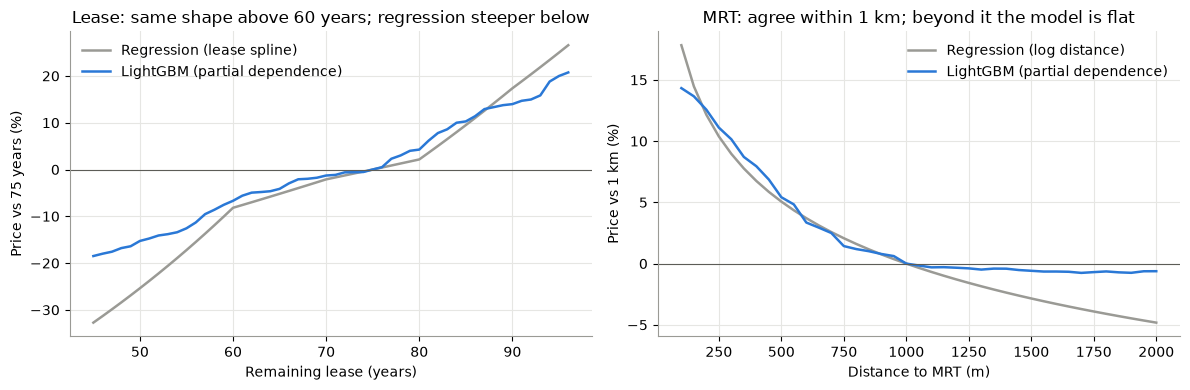

            45.0  50.0  55.0  60.0  65.0  70.0  80.0  85.0  90.0  95.0
regression -32.7 -25.4 -17.2  -8.2  -5.2  -2.1   2.2   9.5  17.4  25.0
LightGBM   -18.5 -15.3 -12.6  -6.7  -4.1  -1.3   4.3  10.3  14.0  20.0
            200.0   300.0   500.0   750.0   1500.0  2000.0
regression    12.2     9.0     5.1     2.1    -2.8    -4.8
LightGBM      12.6    10.1     5.4     1.4    -0.6    -0.6


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
grid = np.arange(45, 97, 1.0)
spl = np.array([[g_, *(max(g_ - k, 0) for k in [60, 70, 80, 90])] for g_ in grid]) @ b[SPL].to_numpy()
pd_g = []
s3 = smp.sample(1500, random_state=2)
for g_ in grid: s4 = s3.assign(remaining_lease_yrs=g_); pd_g.append(gbm(s4).mean())
ref = np.where(grid == 75)[0][0]
ax[0].plot(grid, (np.exp(spl - spl[ref]) - 1) * 100, color=GREY, label="Regression (lease spline)")
ax[0].plot(grid, (np.exp(np.array(pd_g) - pd_g[ref]) - 1) * 100, color=BLUE, label="LightGBM (partial dependence)")
ax[0].axhline(0, color="#5c5c57", lw=0.8); ax[0].set(xlabel="Remaining lease (years)", ylabel="Price vs 75 years (%)", title="Lease: same shape above 60 years; regression steeper below"); ax[0].legend()
gm = np.arange(100, 2001, 50.0)
pd_m = [gbm(s3.assign(dist_mrt_m=g_)).mean() for g_ in gm]; r2 = np.where(gm == 1000)[0][0]
ax[1].plot(gm, (np.exp(b["log_mrt"] * (np.log(gm) - np.log(1000))) - 1) * 100, color=GREY, label="Regression (log distance)")
ax[1].plot(gm, (np.exp(np.array(pd_m) - pd_m[r2]) - 1) * 100, color=BLUE, label="LightGBM (partial dependence)")
ax[1].axhline(0, color="#5c5c57", lw=0.8); ax[1].set(xlabel="Distance to MRT (m)", ylabel="Price vs 1 km (%)", title="MRT: agree within 1 km; beyond it the model is flat"); ax[1].legend()
plt.tight_layout(); plt.show()
lease_tab = pd.DataFrame({"regression": (np.exp(spl - spl[ref]) - 1) * 100, "LightGBM": (np.exp(np.array(pd_g) - pd_g[ref]) - 1) * 100}, index=grid).loc[[45, 50, 55, 60, 65, 70, 80, 85, 90, 95]]
print(lease_tab.round(1).T.to_string())
mrt_tab = pd.DataFrame({"regression": (np.exp(b["log_mrt"] * (np.log(gm) - np.log(1000))) - 1) * 100, "LightGBM": (np.exp(np.array(pd_m) - pd_m[r2]) - 1) * 100}, index=gm).loc[[200, 300, 500, 750, 1500, 2000]]
print(mrt_tab.round(1).T.to_string())

**Out of sample.** The same unseen-block split as notebooks 04 and 04b (20% of blocks). Two richer regressions test how much of the gap to LightGBM is
interactions: town-specific slopes for floor area and lease (the top SHAP interactions in 04b §6), then also region-specific month effects.

In [5]:
TW = sorted(d["town"].unique())[1:]; INT = []
for i_, t_ in enumerate(TW):                     # town-specific slopes as explicit columns (pyfixest cannot predict new data with i())
    d[f"ta{i_}"] = (d["town"] == t_) * (d["log_area"] - d["log_area"].mean()); d[f"tl{i_}"] = (d["town"] == t_) * (d["remaining_lease_yrs"] - 70)
    INT += [f"ta{i_}", f"tl{i_}"]
d["region_month"] = d["region"] + "|" + d["month"]
rng = np.random.default_rng(0); blocks = d["address"].unique()
te = d["address"].isin(set(rng.choice(blocks, int(len(blocks) * 0.2), replace=False))).to_numpy()
tr_d, te_d = d[~te], d[te]
def mape(f, ylog=True):
    m = pf.feols(f, data=tr_d); p = m.predict(newdata=te_d)
    p = np.exp(p) if ylog else p
    return np.nanmean(np.abs(p / te_d["resale_price"].to_numpy() - 1)), m
specs = {"Semi-log, town + month FE (§1)": f"lp ~ {RHS} | town + month",
         "+ town-specific area and lease slopes": f"lp ~ {RHS} + {' + '.join(INT)} | town + month",
         "+ region × month effects": f"lp ~ {RHS} + {' + '.join(INT)} | town + region_month"}
oos = {k: mape(f)[0] for k, f in specs.items()}
oos["LightGBM (production, notebook 04b)"] = 0.0393
print(pd.Series(oos, name="MAPE, unseen blocks").mul(100).round(2).to_string())
import gc; d.drop(columns=INT, inplace=True); _ = gc.collect()

Semi-log, town + month FE (§1)           6.28
+ town-specific area and lease slopes    5.91
+ region × month effects                 5.72
LightGBM (production, notebook 04b)      3.93


**Finding:** The regression explains 94.5% of the variance in log price (92.2% within town and month; RMSE 0.082 in logs). Every structural attribute has the expected sign, and its implicit price agrees closely with the LightGBM model's:

| Attribute | Regression: % (95% CI) | $ at the median $630,000 | LightGBM: % | $ |
|---|---|---|---|---|
| +1 sqm floor area | 0.81 (0.78–0.83) | 5,080 | 0.74 | 4,630 |
| +3 floors (one storey range) | 2.04 (2.00–2.07) | 12,830 | 2.01 | 12,660 |
| MRT distance halved | 5.06 (4.84–5.28) | 31,900 | 4.26 | 26,860 |
| +1 year of lease at 60–70 years | 0.64 (0.59–0.69) | 4,050 | 0.42 | 2,620 |
| +1 year of lease at 70–80 years | 0.43 (0.37–0.49) | 2,690 | 0.28 | 1,780 |
| +1 year of lease at 50–60 years | 2.10 (1.98–2.21) | 13,200 | 0.91 | 5,730 |
| +1 year of lease at 80–90 years | 1.40 (1.34–1.46) | 8,800 | 0.49 | 3,100 |

- **Lease:** both models find the same shape (a plateau from about 60 to 80 years, steeper either side), but the regression's ends are two to three times as steep. One lease slope is imposed on every town, so it absorbs what LightGBM attributes to lease × town and lease × time interactions (notebook 04b §6). Short leases are concentrated in older central towns, and long leases in new estates whose newness carries its own premium.
- **MRT:** within 1 km the two curves coincide (+5.1% against +5.4% at 500 m, relative to 1 km). Beyond 1 km the log form keeps falling (−4.8% at 2 km) while LightGBM is flat (−0.6%). The walking catchment ends at about 1 km, and the log specification is wrong in the tail.
- **Standard errors:** block-clustered errors are 3.8 times the naive ones (median; range 1.6–5.8) and 3.0 times the heteroskedasticity-robust ones. Sales in a block share unobserved quality. Ignoring this would overstate precision far more than in the survival model (1.3–1.8×).
- **Amenities:** the smaller amenity terms are associations, not causal effects. For example, more primary schools within 1 km goes with a 0.4% *lower* price each, because they cluster in older, denser estates.
- **Out of sample** (unseen blocks): MAPE is 6.28% for the regression, 5.91% with town-specific area and lease slopes, and 5.72% with region-specific market timing as well, against 3.93% for LightGBM. Hand-specified interactions close only a quarter of the gap. The rest is non-linearity and higher-order interactions that the trees find automatically, so LightGBM stays the production model. The regression supplies implicit prices with confidence intervals.

## 2 · Specification diagnostics

In [6]:
# 2a · Multicollinearity: VIF of each regressor after partialling out the fixed effects and dummies (the within variation that identifies β),
# on a 60,000-sale sample: VIF_j = j-th diagonal of the inverse correlation matrix of the residualised regressors
s = d.sample(60_000, random_state=6)
Dm_ = pd.get_dummies(s[["town", "month", "flat_type", "flat_model_group"]].astype(str), dtype=float).to_numpy()
VX = [c for c in CONT if not c.startswith("lease_gt")]
Rx = s[VX].to_numpy(float); Rx = Rx - Dm_ @ np.linalg.lstsq(Dm_, Rx, rcond=None)[0]
rows = [{"regressor": x, "VIF (within)": v} for x, v in zip(VX, np.diag(np.linalg.inv(np.corrcoef(Rx, rowvar=False))))]
Rs = s[CONT].to_numpy(float); Rs = Rs - Dm_ @ np.linalg.lstsq(Dm_, Rs, rcond=None)[0]
print("With the lease spline terms included, the lease terms' VIFs are:", dict(zip(SPL, np.round(np.diag(np.linalg.inv(np.corrcoef(Rs, rowvar=False)))[1:6], 1))), "(collinear by construction)")
del Dm_, Rx, Rs
vif = pd.DataFrame(rows).set_index("regressor"); print(vif.round(2).to_string())

With the lease spline terms included, the lease terms' VIFs are: {'remaining_lease_yrs': np.float64(30.8), 'lease_gt60': np.float64(62.1), 'lease_gt70': np.float64(47.7), 'lease_gt80': np.float64(21.4), 'lease_gt90': np.float64(5.1)} (collinear by construction)
                     VIF (within)
regressor                        
log_area                     1.20
remaining_lease_yrs          1.47
storey_mid                   1.25
max_floor_lvl                1.54
log_mrt                      1.21
log_hawker                   1.08
log_park                     1.09
log_supermarket              1.39
log_polyclinic               1.14
log_primary                  1.12
n_primary_1km                1.31
n_preschool_500m             1.28
n_chas_500m                  1.54
n_supermarket_500m           1.75


In [7]:
# 2b · Heteroskedasticity: Koenker's studentised Breusch–Pagan test (n·R² of e² on the regressors)
e = ols.resid(); d["e2"] = e ** 2; d["fitted"] = d["lp"] - e
bp = pf.feols(f"e2 ~ {RHS} | town + month", data=d); LM = len(d) * bp._r2; k_ = len(bp.coef()) + d["town"].nunique() - 1 + d["month"].nunique() - 1
print(f"Breusch–Pagan (Koenker): LM = {LM:,.0f} on {k_} df, p = {stats.chi2.sf(LM, k_):.2g}")
sd_by = pd.DataFrame({"res": e, "dec": pd.qcut(d["fitted"], 10, labels=range(1, 11)), "ft": d["flat_type"]})
print("Residual SD by fitted-price decile:", sd_by.groupby("dec")["res"].std().round(4).tolist())
print("Residual SD by flat type:", sd_by.groupby("ft")["res"].std().reindex(K.TYPES).round(4).to_dict())

Breusch–Pagan (Koenker): LM = 25,238 on 175 df, p = 0
Residual SD by fitted-price decile: [0.0951, 0.0823, 0.0828, 0.0804, 0.0806, 0.0803, 0.079, 0.078, 0.0803, 0.0792]
Residual SD by flat type: {'2 ROOM': 0.0969, '3 ROOM': 0.0909, '4 ROOM': 0.0762, '5 ROOM': 0.0818, 'EXECUTIVE': 0.0823}


In [8]:
# 2c · Functional form. (i) Box–Cox on price: profile log-likelihood of λ (sample of 60,000 sales)
s = d.sample(60_000, random_state=3).copy(); gm_y = np.exp(np.log(s["resale_price"]).mean())
lam_grid = np.round(np.arange(-0.3, 0.31, 0.05), 2); ll = []
for lam in lam_grid:
    s["yb"] = np.log(s["resale_price"] / gm_y) if abs(lam) < 1e-9 else ((s["resale_price"] / gm_y) ** lam - 1) / lam   # scaled by the geometric mean: comparable RSS
    r = pf.feols(f"yb ~ {RHS} | town + month", data=s).resid(); ll.append(-len(s) / 2 * np.log(np.mean(r ** 2)))
ll = np.array(ll); k0 = ll.argmax(); sl = slice(max(k0 - 2, 0), k0 + 3)
c2, c1, c0 = np.polyfit(lam_grid[sl], ll[sl], 2); lam_hat = -c1 / (2 * c2); half = np.sqrt(stats.chi2.ppf(0.95, 1) / 2 / -c2)
ci = np.array([lam_hat - half, lam_hat + half])
print(f"Box–Cox λ̂ = {lam_hat:.2f} (95% CI {ci.min():.2f} to {ci.max():.2f}); λ = 0 is the log model, λ = 1 the linear one")
print("Log-likelihood vs log model:", dict(zip(lam_grid, (ll - ll[np.argmin(np.abs(lam_grid))]).round(0))))
# (ii) Linear, semi-log and log-log, out of sample
RHS_lin_area = RHS.replace("log_area", "floor_area_sqm")
ff = {"Linear: price on area": (f"resale_price ~ {RHS_lin_area} | town + month", False),
      "Semi-log: log price on area": (f"lp ~ {RHS_lin_area} | town + month", True),
      "Log-log in area (§1)": (f"lp ~ {RHS} | town + month", True)}
print(pd.Series({k: mape(f, yl)[0] * 100 for k, (f, yl) in ff.items()}, name="MAPE, unseen blocks (%)").round(2).to_string())

Box–Cox λ̂ = 0.03 (95% CI 0.02 to 0.04); λ = 0 is the log model, λ = 1 the linear one
Log-likelihood vs log model: {np.float64(-0.3): np.float64(-2298.0), np.float64(-0.25): np.float64(-1659.0), np.float64(-0.2): np.float64(-1118.0), np.float64(-0.15): np.float64(-678.0), np.float64(-0.1): np.float64(-343.0), np.float64(-0.05): np.float64(-116.0), np.float64(-0.0): np.float64(0.0), np.float64(0.05): np.float64(4.0), np.float64(0.1): np.float64(-104.0), np.float64(0.15): np.float64(-325.0), np.float64(0.2): np.float64(-657.0), np.float64(0.25): np.float64(-1099.0), np.float64(0.3): np.float64(-1648.0)}


Linear: price on area          8.10
Semi-log: log price on area    6.31
Log-log in area (§1)           6.28


In [9]:
# 2c (iii) · Ramsey RESET: add powers of the fitted value; Wald test with block-clustered errors
z = (d["fitted"] - d["fitted"].mean()) / d["fitted"].std(); d["yh2"], d["yh3"] = z ** 2, z ** 3
rs = pf.feols(f"lp ~ {RHS} + yh2 + yh3 | town + month", data=d, vcov={"CRV1": "address"})
bb = rs.coef()[["yh2", "yh3"]].to_numpy(); idx = [list(rs.coef().index).index(c) for c in ["yh2", "yh3"]]
W = bb @ np.linalg.inv(rs._vcov[np.ix_(idx, idx)]) @ bb
print(f"RESET: Wald = {W:.1f} on 2 df, p = {stats.chi2.sf(W, 2):.2g} · coefficients {bb.round(4)}")

RESET: Wald = 349.1 on 2 df, p = 1.5e-76 · coefficients [ 0.0009 -0.0048]


In [10]:
# 2d · Influence (Cook's distance, sample of 40,000 with explicit dummies) and error tails
s = d.sample(40_000, random_state=4)
Xs = pd.concat([s[CONT], pd.get_dummies(s[["flat_type", "flat_model_group", "town", "month"]].astype(str), drop_first=True, dtype=float)], axis=1)
Xs = sm.add_constant(Xs.loc[:, Xs.std() > 0]); fit_s = sm.OLS(s["lp"].to_numpy(), Xs.to_numpy(float)).fit()
cd = fit_s.get_influence().cooks_distance[0]; hi = cd > 4 / len(s)
fit_c = sm.OLS(s["lp"].to_numpy()[~hi], Xs.to_numpy(float)[~hi]).fit()
cols = list(Xs.columns); key = ["log_area", "remaining_lease_yrs", "storey_mid", "log_mrt", "log_hawker", "log_park"]
inf = pd.DataFrame({"all": [fit_s.params[cols.index(k)] for k in key], f"without {hi.sum()} influential": [fit_c.params[cols.index(k)] for k in key]}, index=key)
inf["change (%)"] = (inf.iloc[:, 1] / inf.iloc[:, 0] - 1) * 100
print(f"Cook's D > 4/n: {hi.mean():.1%} of sales · max D {cd.max():.4f}"); print(inf.round(4).to_string())
r = ols.resid(); zr = (r - r.mean()) / r.std()
print(f"Residuals: skew {stats.skew(r):.2f} · excess kurtosis {stats.kurtosis(r):.2f} · beyond ±3σ {np.mean(np.abs(zr) > 3):.2%} (normal: 0.27%)")

Cook's D > 4/n: 5.6% of sales · max D 0.0045
                        all  without 2246 influential  change (%)
log_area             0.7485                    0.7353     -1.7594
remaining_lease_yrs  0.0204                    0.0214      4.7947
storey_mid           0.0066                    0.0066      0.0558
log_mrt             -0.0719                   -0.0730      1.5106
log_hawker          -0.0092                   -0.0081    -11.6943
log_park            -0.0121                   -0.0084    -30.7971
Residuals: skew 0.22 · excess kurtosis 1.49 · beyond ±3σ 0.80% (normal: 0.27%)


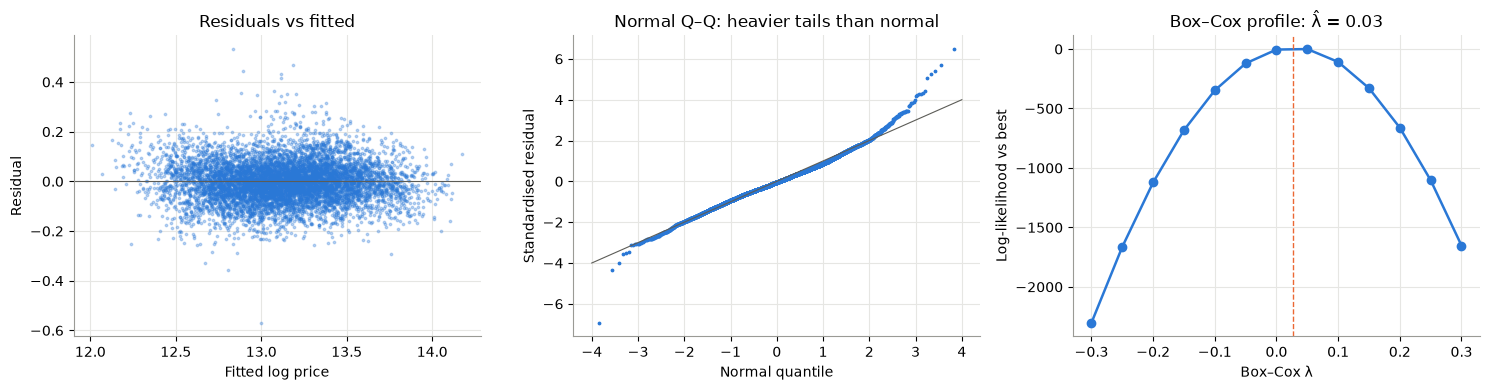

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ss = np.random.default_rng(5).choice(len(d), 8000, replace=False)
ax[0].scatter(d["fitted"].to_numpy()[ss], e.to_numpy()[ss] if hasattr(e, "to_numpy") else e[ss], s=3, alpha=0.3, color=BLUE); ax[0].axhline(0, color="#5c5c57", lw=0.8)
ax[0].set(xlabel="Fitted log price", ylabel="Residual", title="Residuals vs fitted")
q = np.sort(zr[ss]); th = stats.norm.ppf((np.arange(1, len(q) + 1) - 0.5) / len(q))
ax[1].scatter(th, q, s=3, color=BLUE); ax[1].plot([-4, 4], [-4, 4], color="#5c5c57", lw=0.8)
ax[1].set(xlabel="Normal quantile", ylabel="Standardised residual", title="Normal Q–Q: heavier tails than normal")
ax[2].plot(lam_grid, ll - ll.max(), marker="o", color=BLUE); ax[2].axvline(lam_hat, color=ORANGE, lw=1, ls="--")
ax[2].set(xlabel="Box–Cox λ", ylabel="Log-likelihood vs best", title=f"Box–Cox profile: λ̂ = {lam_hat:.2f}")
plt.tight_layout(); plt.show()

**Finding:** The specification passes the checks that matter, and the checks that fail point to the production design:

| Check | Result | Consequence |
|---|---|---|
| Multicollinearity (within VIF) | 1.1–1.8 for every regressor | No problem. The lease-spline terms are collinear by construction (VIF 5–62), but their segment slopes are precisely estimated |
| Heteroskedasticity (Koenker–Breusch–Pagan) | LM = 25,238 on 175 df, p ≈ 0. Residual SD 0.095 in the cheapest decile against 0.078–0.083 elsewhere; 0.097 for 2-room against 0.076 for 4-room | Clustered, heteroskedasticity-robust errors; Mondrian intervals by flat type (04b §5) |
| Functional form, Box–Cox | λ̂ = 0.03 (95% CI 0.02–0.04). The log model is within 4 log-likelihood points of the best; λ = ±0.1 already loses 100–340 | Log price is right |
| Functional form, out of sample | Linear price 8.10% MAPE; semi-log in area 6.31%; log-log in area 6.28% | Log-log in floor area kept |
| RESET | Wald = 349 on 2 df, p < 10⁻⁷⁰ | Non-linearity remains (e.g. the MRT tail in §1), which is why a flexible model wins |
| Influence (Cook's D) | 5.6% of sales above 4/n, but the largest D is 0.0045. Dropping them moves area, lease, storey and MRT by under 5%; hawker and park move 12–31% | No single sale drives the results; the small amenity coefficients are fragile and not interpreted |
| Error tails | Excess kurtosis 1.5; 0.80% of residuals beyond ±3σ against 0.27% for a normal | Normal-theory intervals are too narrow in the tails; conformal intervals are used instead (04b §5) |

## 3 · Spatial dependence
The sales-level model treats each sale as independent once town is controlled for. Nearby blocks share unmeasured location quality, so
errors are likely correlated in space. That is tested on a **block-level** model, the standard set-up for spatial econometrics:

1. **Block value.** A regression with block and month fixed effects and flat attributes (log area, storey, flat type, flat model) gives each block's quality-adjusted price level.
2. **Explaining block value.** Block value is regressed on location (log distances, amenity counts), block height and remaining lease in 2022, for blocks with 10+ sales.
3. **Spatial weights.** Each block's 8 nearest blocks, row-standardised.

Spatial models are then fitted: **SEM** (error model, $u = \lambda W u + \varepsilon$: correlated omitted location quality) and **SAR** (lag model,
$y = \rho W y + X\beta + \varepsilon$: prices spill over, as when valuers price off nearby sales).

In [12]:
import spreg, libpysal
from esda.moran import Moran
t1 = time.time()
st1 = pf.feols("lp ~ log_area + storey_mid + C(flat_type) + C(flat_model_group) | address + month", data=d)
fe = pd.Series(st1.fixef()["C(address)"]); fe.index = fe.index.astype(str)
DC = [f"dist_{c}_m" for c in DIST if c != "mrt"] + ["dist_mrt_now_m"]
bk = d.groupby("address").agg(n=("lp", "size"), town=("town", "first"), lat=("lat", "first"), lon=("lon", "first"),
                              lease_start=("lease_commence_date", lambda x: x.mode()[0]), max_floor_lvl=("max_floor_lvl", "first"),
                              **{c: (c, "first") for c in DC + ["n_primary_1km", "n_chas_500m", "n_supermarket_500m"]})
bk["y"] = fe.reindex(bk.index); bk = bk[bk["n"] >= 10].dropna()
bk["y"] -= bk["y"].mean()
bk["lease22"] = 99 - (2022 - bk["lease_start"]); bk["lease22_gt70"] = (bk["lease22"] - 70).clip(lower=0); bk["lease22_gt85"] = (bk["lease22"] - 85).clip(lower=0)
for c in DIST: bk["log_" + c] = np.log(bk[f"dist_{c}_m" if c != "mrt" else "dist_mrt_now_m"].clip(lower=50))
XB = ["log_" + c for c in DIST] + ["n_primary_1km", "n_chas_500m", "n_supermarket_500m", "max_floor_lvl", "lease22", "lease22_gt70", "lease22_gt85"]
xy = np.c_[(bk["lon"] - 103.8) * 111_320 * np.cos(np.radians(1.35)), (bk["lat"] - 1.35) * 110_574]
w = libpysal.weights.KNN.from_array(xy, k=8); w.transform = "r"
yb, Xb = bk[["y"]].to_numpy(), bk[XB].to_numpy()
TD = pd.get_dummies(bk["town"], drop_first=True, dtype=float)
print(f"{len(bk):,} blocks with 10+ sales · stage 1 within-R² {st1._r2_within:.3f} · {time.time() - t1:.0f}s")
o1 = spreg.OLS(yb, Xb, w=w, spat_diag=True, moran=True, name_x=XB, name_y="block value")
o2 = spreg.OLS(yb, np.c_[Xb, TD.to_numpy()], w=w, spat_diag=True, moran=True, name_x=XB + list(TD.columns), name_y="block value")
diag = pd.DataFrame({m_: {"R²": o.r2, "Moran's I of residuals": o.moran_res[0], "LM error": o.lm_error[0], "LM lag": o.lm_lag[0],
                         "robust LM error": o.rlm_error[0], "robust LM lag": o.rlm_lag[0]} for m_, o in [("OLS", o1), ("OLS + town dummies", o2)]})
print(diag.round(3).to_string()); print("(all LM tests: p < 0.001 unless shown otherwise)", {m_: (o.rlm_lag[1]) for m_, o in [("OLS", o1), ("OLS + town", o2)]})

8,555 blocks with 10+ sales · stage 1 within-R² 0.778 · 5s


                              OLS  OLS + town dummies
R²                          0.563               0.863
Moran's I of residuals      0.806               0.605
LM error                24202.722           13628.898
LM lag                  14660.147            4183.221
robust LM error          9613.769            9461.964
robust LM lag              71.194              16.288
(all LM tests: p < 0.001 unless shown otherwise) {'OLS': np.float64(3.238157302525268e-17), 'OLS + town': np.float64(5.440688674088079e-05)}


In [13]:
t1 = time.time()
sem_ml = spreg.ML_Error(yb, Xb, w=w, method="LU", name_x=XB)
sem_ml_t = spreg.ML_Error(yb, np.c_[Xb, TD.to_numpy()], w=w, method="LU", name_x=XB + list(TD.columns))
sem_gm = spreg.GM_Error_Het(yb, Xb, w=w, name_x=XB)
sar = spreg.GM_Lag(yb, Xb, w=w, name_x=XB, spat_impacts="simple", robust="white")
print(f"spatial models fitted in {time.time() - t1:.0f}s · SEM λ (ML) {sem_ml.lam:.3f} · SEM λ (ML, with town) {sem_ml_t.lam:.3f} · SEM λ (GMM, het-robust) {sem_gm.betas[-1][0]:.3f} · SAR ρ {sar.rho[0]:.3f}")
def cs(o, j, k=None):
    v = o.betas[j][0]; s_ = np.sqrt(o.vm[j, j]); return v, s_
j = 1 + XB.index("log_mrt")
comp = {"OLS (block)": cs(o1, j), "OLS + town dummies": cs(o2, j), "SEM (ML)": cs(sem_ml, j), "SEM (ML) + town dummies": cs(sem_ml_t, j),
        "SEM (GMM, heteroskedasticity-robust)": cs(sem_gm, j), "SAR direct effect": (sar.betas[j][0], np.sqrt(sar.vm[j, j]))}
sar_tot = sar.betas[j][0] / (1 - sar.rho[0])
comp["SAR total effect (incl. spillover)"] = (sar_tot, np.nan)
comp["Sales-level FE regression (§1)"] = (b["log_mrt"], T.loc["log_mrt", "Std. Error"])
mrt_cmp = pd.DataFrame(comp, index=["MRT elasticity", "SE"]).T
mrt_cmp["price effect of halving MRT distance (%)"] = (np.exp(-mrt_cmp["MRT elasticity"] * np.log(2)) - 1) * 100
print(mrt_cmp.round(4).to_string())
coef_all = pd.DataFrame({"OLS": o1.betas[1:len(XB) + 1, 0], "OLS + town": o2.betas[1:len(XB) + 1, 0], "SEM (ML)": sem_ml.betas[1:len(XB) + 1, 0],
                         "SEM (ML) + town": sem_ml_t.betas[1:len(XB) + 1, 0]}, index=XB)
print(coef_all.round(4).to_string())
for kk in [4, 15]:
    wk = libpysal.weights.KNN.from_array(xy, k=kk); wk.transform = "r"
    sk = spreg.ML_Error(yb, Xb, w=wk, method="LU", name_x=XB)
    print(f"Robustness, k = {kk} neighbours: SEM λ {sk.lam:.3f}, MRT elasticity {sk.betas[j][0]:.4f} (SE {np.sqrt(sk.vm[j, j]):.4f})")
print("Moran's I of SEM (ML) filtered residuals:", round(Moran(sem_ml.e_filtered.flatten(), w, permutations=0).I, 3))

ML_Error


ML_Error


GM_Error_Het
GM_Lag
spatial models fitted in 63s · SEM λ (ML) 0.950 · SEM λ (ML, with town) 0.852 · SEM λ (GMM, het-robust) 0.938 · SAR ρ 0.315
                                      MRT elasticity      SE  price effect of halving MRT distance (%)
OLS (block)                                  -0.0877  0.0020                                    6.2663
OLS + town dummies                           -0.0743  0.0013                                    5.2834
SEM (ML)                                     -0.0379  0.0029                                    2.6609
SEM (ML) + town dummies                      -0.0451  0.0025                                    3.1726
SEM (GMM, heteroskedasticity-robust)         -0.0496  0.0045                                    3.4954
SAR direct effect                            -0.0640  0.0024                                    4.5387
SAR total effect (incl. spillover)           -0.0934     NaN                                    6.6902
Sales-level FE regression (§1)  

ML_Error
Robustness, k = 4 neighbours: SEM λ 0.927, MRT elasticity -0.0365 (SE 0.0032)


ML_Error
Robustness, k = 15 neighbours: SEM λ 0.966, MRT elasticity -0.0465 (SE 0.0025)
Moran's I of SEM (ML) filtered residuals: -0.03


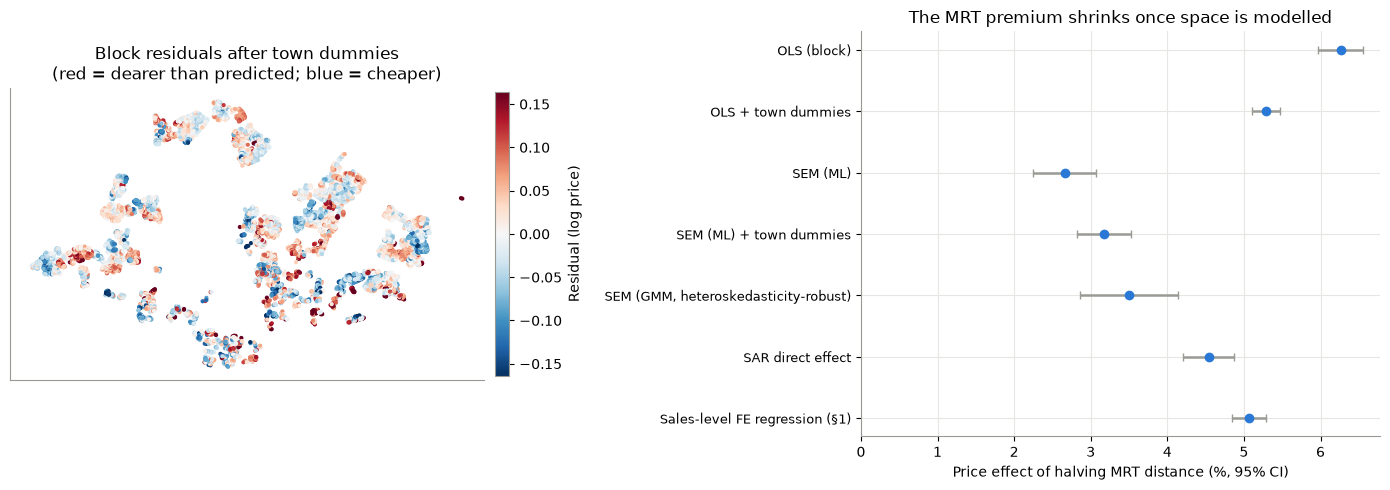

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.1, 1]})
res = o2.u.flatten(); lim = np.quantile(np.abs(res), 0.98)
sc = ax[0].scatter(bk["lon"], bk["lat"], c=res, cmap="RdBu_r", vmin=-lim, vmax=lim, s=4)
ax[0].set(title="Block residuals after town dummies\n(red = dearer than predicted; blue = cheaper)", xticks=[], yticks=[]); ax[0].set_aspect(1); ax[0].grid(False)
plt.colorbar(sc, ax=ax[0], shrink=0.7, pad=0.02, label="Residual (log price)")
mc = mrt_cmp.drop("SAR total effect (incl. spillover)").iloc[::-1]
eff = (np.exp(-mc["MRT elasticity"] * np.log(2)) - 1) * 100
lo = (np.exp(-(mc["MRT elasticity"] + 1.96 * mc["SE"]) * np.log(2)) - 1) * 100; hi_ = (np.exp(-(mc["MRT elasticity"] - 1.96 * mc["SE"]) * np.log(2)) - 1) * 100
ax[1].errorbar(eff, range(len(mc)), xerr=[eff - lo, hi_ - eff], fmt="o", color=BLUE, ecolor=GREY, capsize=3)
ax[1].set_yticks(range(len(mc))); ax[1].set_yticklabels(mc.index, fontsize=9); ax[1].set_xlim(left=0)
ax[1].set(xlabel="Price effect of halving MRT distance (%, 95% CI)", title="The MRT premium shrinks once space is modelled")
plt.tight_layout(); plt.show()

**Finding:** Ignoring space roughly doubles the MRT premium and understates its uncertainty.

- **Residuals cluster.** For 8,555 blocks, the block-level OLS residuals have Moran's I of 0.81, and still 0.60 with town dummies. Within towns, neighbouring blocks share value the regression does not measure. LightGBM's residuals (0.07, notebook 04b) are far less clustered.
- **The tests choose the error model.** The robust LM-error statistic (9,462–9,614) dwarfs the robust LM-lag statistic (16–71). By Anselin's decision rule this is omitted, spatially smooth location quality (neighbourhood character, estate age, views), not prices spilling over between blocks. The spatial-error model's λ is 0.95 (0.85 with town dummies), and its filtered residuals have Moran's I of −0.03, so the dependence is fully absorbed.
- **Effect of halving MRT distance:**

  | Model | Effect |
  |---|---|
  | OLS | 6.3% |
  | OLS + town dummies | 5.3% |
  | Spatial error (ML) | 2.7% |
  | Spatial error + town dummies | 3.2% |
  | Spatial error (GMM, heteroskedasticity-robust) | 3.5% |
  | Spatial lag, direct effect | 4.5% |

  The result holds with 4 or 15 neighbours (MRT elasticity −0.037 and −0.047). Blocks near MRT also sit in neighbourhoods valued for other reasons, and a non-spatial model credits that value to the MRT. The hawker, park and supermarket effects shrink even more (3–11 times), while the lease and block-height effects are stable.
- **Implication.** For *prediction*, nothing changes: LightGBM leaves little spatial structure. For *interpretation*, the MRT premium read from a non-spatial model (including LightGBM's 4.3%) is an upper bound. About 3% per halving of distance is the spatially robust figure to hand to the Preference Lead.

## 4 · New MRT stations: difference-in-differences
**Design.** A block is *treated* when a station opening between Jun 2018 and Mar 2025 brings it from more than 800 m to within 800 m of a
station. *Controls* are blocks in the same towns whose nearest station never changed over 2017–2026. The regression compares the same
block-and-flat-type before and after opening, against controls in the same town and month:

$$\ln P_{it} = \theta\,(\text{treated}_b \times \text{post}_{bt}) + X_{it}'\beta + \mu_{b \times \text{flat type}} + \tau_{\text{town} \times t} + \varepsilon_{it}$$

Town × month effects remove anything that moved the whole town (including other new amenities and the market cycle). The **event study**
replaces the single post indicator with 6-month bins of time since opening (the 6 months before opening are the reference), which shows
whether prices were already moving before the opening.

In [15]:
import gc; del st1, sem_ml_t, sar, sem_gm; gc.collect()
addr, Dm, stn, opened = K._station_distances()
opened = pd.to_datetime(pd.Series(opened)); stn = pd.Series(stn).str.title()
old_net = (opened.isna() | (opened < "2018-01-01")).to_numpy(); base = Dm[:, old_net].min(1)
win = np.where(((opened >= "2018-06-01") & (opened <= "2025-03-31")).to_numpy())[0]
later = np.where((opened >= "2018-01-01").to_numpy())[0]
changed = (Dm[:, later] < base[:, None]).any(1)
def treatment(thr):
    td, ts = [], []
    for i in range(len(addr)):
        c = sorted([(opened[j], j) for j in win if Dm[i, j] <= thr and base[i] > thr])
        td.append(c[0][0] if c else pd.NaT); ts.append(stn[c[0][1]] if c else None)
    return pd.DataFrame({"address": addr, "treat_date": td, "station": ts, "changed": changed, "base_dist": base})
def did_frame(thr):
    B = treatment(thr); g = d[["address", "town", "month", "flat_type", "lp", "log_area", "storey_mid", "remaining_lease_yrs"]].merge(B, on="address", how="left")
    g = g[g["treat_date"].notna() | ~g["changed"].astype(bool)]
    g = g[g["town"].isin(g.loc[g["treat_date"].notna(), "town"].unique())].copy()
    md = pd.to_datetime(g["month"] + "-01")
    g["ev"] = (md.dt.year - g["treat_date"].dt.year) * 12 + (md.dt.month - g["treat_date"].dt.month)
    g["treated"] = g["treat_date"].notna().astype(int); g["post"] = ((g["treated"] == 1) & (g["ev"] >= 0)).astype(int)
    g["lease2"] = g["remaining_lease_yrs"] ** 2 / 100; g["unit"] = g["address"] + "|" + g["flat_type"]; g["town_month"] = g["town"] + "|" + g["month"]
    return g, B
g, B = did_frame(800)
tb_ = B[B["treat_date"].notna()]
print(f"Treated: {len(tb_)} blocks, {g['treated'].sum():,} sales · controls: {g.loc[g.treated == 0, 'address'].nunique():,} blocks, {(g.treated == 0).sum():,} sales · {g['town'].nunique()} towns")
print(tb_.groupby(["treat_date", "station"]).size().rename("blocks").to_string())
DID = "lp ~ post + log_area + storey_mid + lease2 | unit + town_month"
m0 = pf.feols(DID, data=g, vcov={"CRV1": "address"})
th = m0.tidy().loc["post"]; print(f"\nPooled DiD: θ = {th['Estimate']:.4f} (SE {th['Std. Error']:.4f}) → {np.expm1(th['Estimate']) * 100:+.1f}% (95% CI {np.expm1(th['2.5%']) * 100:+.1f}% to {np.expm1(th['97.5%']) * 100:+.1f}%)")

Treated: 281 blocks, 7,543 sales · controls: 2,766 blocks, 74,256 sales · 8 towns
treat_date  station        
2019-11-02  Canberra           57
2020-01-31  Woodlands North     4
            Woodlands South    29
2021-08-28  Bright Hill        49
            Lentor             15
            Mayflower          45
            Upper Thomson       1
2024-06-23  Bayshore           19
            Marine Parade      47
            Marine Terrace      7
2024-12-10  Punggol Coast       8



Pooled DiD: θ = 0.0280 (SE 0.0042) → +2.8% (95% CI +2.0% to +3.7%)


            Estimate  2.5%  97.5%
≤ −31          -1.70 -2.91  -0.48
-30 to -25     -1.25 -2.63   0.15
-24 to -19     -0.78 -2.21   0.68
-18 to -13     -1.56 -2.96  -0.15
-12 to -7      -0.55 -1.64   0.55
-6 to -1        0.00  0.00   0.00
+0 to +5        0.94 -0.10   2.00
+6 to +11       2.13  0.98   3.28
+12 to +17      1.62  0.45   2.81
+18 to +23      1.57  0.38   2.77
≥ +24           1.77  0.73   2.82


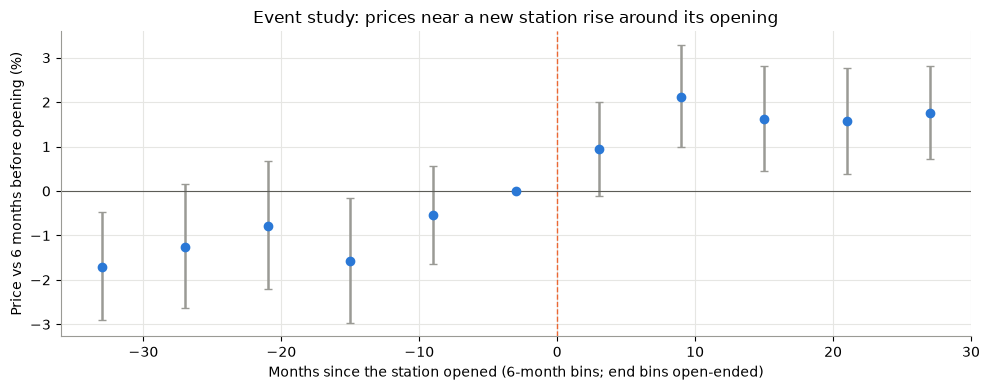

Mean of pre-opening bins: -1.17% · mean of post bins: +1.61%


In [16]:
bins = list(range(-6, 5)); evb = np.where(g["treated"] == 1, np.floor(g["ev"] / 6).clip(-6, 4), -99).astype(int)
E = []
for k in bins:
    if k == -1: continue
    g[f"b{k + 6}"] = (evb == k).astype(int); E.append(f"b{k + 6}")
me = pf.feols(f"lp ~ {' + '.join(E)} + log_area + storey_mid + lease2 | unit + town_month", data=g, vcov={"CRV1": "address"})
es = me.tidy().loc[E, ["Estimate", "2.5%", "97.5%"]]; es.index = [(int(e[1:]) - 6) * 6 for e in E]
es.loc[-6] = 0.0; es = es.sort_index()
lab = {k: ("≤ −31" if k == -36 else f"≥ +24" if k == 24 else f"{k:+d} to {k + 5:+d}") for k in es.index}
print((es.apply(np.expm1) * 100).round(2).rename(index=lab).to_string())
fig, ax = plt.subplots(figsize=(10, 4))
x = es.index + 3; yv = np.expm1(es["Estimate"]) * 100
ax.errorbar(x, yv, yerr=[yv - np.expm1(es["2.5%"]) * 100, np.expm1(es["97.5%"]) * 100 - yv], fmt="o", color=BLUE, ecolor=GREY, capsize=3)
ax.axvline(0, color=ORANGE, lw=1, ls="--"); ax.axhline(0, color="#5c5c57", lw=0.8)
ax.set(xlabel="Months since the station opened (6-month bins; end bins open-ended)", ylabel="Price vs 6 months before opening (%)",
       title="Event study: prices near a new station rise around its opening")
plt.tight_layout(); plt.show()
pre = es.loc[es.index < -6, "Estimate"]; post_ = es.loc[es.index >= 0, "Estimate"]
print(f"Mean of pre-opening bins: {np.expm1(pre.mean()) * 100:+.2f}% · mean of post bins: {np.expm1(post_.mean()) * 100:+.2f}%")

In [17]:
rows = []
for thr in [600, 800, 1000]:
    gg, BB = did_frame(thr) if thr != 800 else (g, B)
    t_ = pf.feols(DID, data=gg, vcov={"CRV1": "address"}).tidy().loc["post"]
    rows.append({"specification": f"Threshold {thr} m", "treated blocks": int(BB["treat_date"].notna().sum()), "θ": t_["Estimate"], "SE": t_["Std. Error"]})
# Gardner (2022) two-stage DiD, robust to staggered timing: unit and town×month effects estimated on not-yet-treated observations only,
# then the residualised price regressed on the treatment indicator (stage-2 SEs clustered by block, not corrected for stage 1)
fs = pf.feols("lp ~ log_area + storey_mid + lease2 | unit + town_month", data=g[g["post"] == 0])
g["lp_adj"] = g["lp"] - fs.predict(newdata=g)
t2 = pf.feols("lp_adj ~ post", data=g.dropna(subset=["lp_adj"]), vcov={"CRV1": "address"}).tidy().loc["post"]
rows.append({"specification": "Two-stage DiD (Gardner), 800 m", "treated blocks": len(tb_), "θ": t2["Estimate"], "SE": t2["Std. Error"]})
# Short window: only the 2 years either side of opening for treated blocks
gw = g[(g["treated"] == 0) | g["ev"].between(-24, 23)]
t3 = pf.feols(DID, data=gw, vcov={"CRV1": "address"}).tidy().loc["post"]
rows.append({"specification": "±24-month window, 800 m", "treated blocks": len(tb_), "θ": t3["Estimate"], "SE": t3["Std. Error"]})
# Placebo: pretend each station opened 24 months early; treated sales after the true opening are dropped
gp = g[(g["treated"] == 0) | (g["ev"] < 0)].copy(); gp["post"] = ((gp["treated"] == 1) & (gp["ev"] >= -24)).astype(int)
t4 = pf.feols(DID, data=gp, vcov={"CRV1": "address"}).tidy().loc["post"]
rows.append({"specification": "Placebo: opening moved 24 months earlier", "treated blocks": len(tb_), "θ": t4["Estimate"], "SE": t4["Std. Error"]})
for s_, gg in g[g["treated"] == 1].groupby("treat_date"):
    sub = g[(g["treated"] == 0) | (g["treat_date"] == s_)]
    try:
        t_ = pf.feols(DID, data=sub, vcov={"CRV1": "address"}).tidy().loc["post"]
        rows.append({"specification": f"Cohort {s_:%b %Y} ({', '.join(sorted(gg['station'].unique()))})", "treated blocks": gg["address"].nunique(), "θ": t_["Estimate"], "SE": t_["Std. Error"]})
    except KeyError:
        rows.append({"specification": f"Cohort {s_:%b %Y} ({', '.join(sorted(gg['station'].unique()))}): not identified", "treated blocks": gg["address"].nunique(), "θ": np.nan, "SE": np.nan})
rob = pd.DataFrame(rows).set_index("specification")
rob["effect (%)"] = np.expm1(rob["θ"]) * 100; rob["95% CI (%)"] = [f"{np.expm1(a - 1.96 * s) * 100:+.1f} to {np.expm1(a + 1.96 * s) * 100:+.1f}" if pd.notna(a) else "" for a, s in zip(rob["θ"], rob["SE"])]
print(rob.round(4).to_string())

                                                                 treated blocks       θ      SE  effect (%)    95% CI (%)
specification                                                                                                            
Threshold 600 m                                                             257  0.0264  0.0044      2.6712  +1.8 to +3.6
Threshold 800 m                                                             281  0.0280  0.0042      2.8432  +2.0 to +3.7
Threshold 1000 m                                                            238  0.0332  0.0063      3.3807  +2.1 to +4.7
Two-stage DiD (Gardner), 800 m                                              281  0.0290  0.0043      2.9423  +2.1 to +3.8
±24-month window, 800 m                                                     281  0.0223  0.0044      2.2579  +1.4 to +3.1
Placebo: opening moved 24 months earlier                                    281  0.0071  0.0047      0.7086  -0.2 to +1.6
Cohort Nov 2019 (Canberr

**Finding:** A new station within 800 m raises nearby resale prices by about 2–3%, part of it before the station opens.

- **Design.** 281 blocks in 8 towns gained a station within 800 m from 11 openings in 2019–2024. The median distance fell from 1,280 m to 340 m. They are compared with 2,766 blocks in the same towns whose nearest station never changed.
- **Pooled estimate: +2.8%** (95% CI +2.0% to +3.7%). It is robust to:

  | Robustness check | Estimate |
  |---|---|
  | 600 m threshold | +2.7% |
  | 1 km threshold | +3.4% |
  | Gardner two-stage estimator (robust to staggered timing) | +2.9% |
  | Window of ±24 months | +2.3% |

- **Timing.** Relative to the 6 months before opening, prices are +0.9% in the first 6 months after and +1.6–2.1% from 6 months onward, with no fade over two years. They were also 1.2–1.7% lower 1.5–3 years before opening, a gradual run-up as completion neared. The placebo, which moves each opening 24 months earlier, gives +0.7% (−0.2% to +1.6%), not significant. So most of the effect arrives at opening, with a smaller anticipation drift before it, consistent with Diao, Leonard and Sing (2017).
- **By cohort.**

  | Cohort | Effect (95% CI) |
  |---|---|
  | Canberra | +1.9% (+0.5% to +3.4%) |
  | Woodlands North/South | +1.5% (+0.6% to +2.4%) |
  | Thomson-East Coast Line stage 2 | +3.5% (+2.3% to +4.7%) |
  | Thomson-East Coast Line stage 4, Marine Parade | +0.8% (−1.5% to +3.1%), only about 2 years of data after opening |

  Punggol Coast (8 blocks) is not identified.
- **Comparison.** A cut from 1,280 m to 340 m would be worth about 10% by the cross-sectional regression (§1), 5–7% by the spatial-error model (§3), and 2.8% causally. Diao, Leonard and Sing found 8.6% for private housing near the Circle Line. Our smaller HDB effect is plausible:
  - HDB estates already have feeder buses.
  - The Thomson-East Coast Line stations were announced in 2012–2014, so some value was capitalised before our data begin.
  - The cross-sectional premium also carries correlated neighbourhood quality (§3).
- **Reconciling with §5.3 of the EDA.** The raw before–after chart there showed no clean step. Once town × month effects remove the market cycle, the step is clear.

## 5 · Summary

**Finding:** The econometric counterpart confirms the production model and sharpens how its effects should be read:

| Question | Answer |
|---|---|
| Do the two schools agree? | Yes on floor area (0.8% per sqm, about $5,000), storey (2.0% per storey range, about $12,800) and MRT within 1 km (about 5% per halving). They disagree only where the regression's functional form is too rigid: the ends of the lease curve and MRT beyond 1 km |
| Why LightGBM for production? | It is 2.4 points of MAPE better on unseen blocks; hand-specified interactions close only a quarter of that gap; RESET rejects the linear index |
| Is the regression well specified? | Log price confirmed by Box–Cox (λ̂ = 0.03); no multicollinearity (VIF ≤ 1.8); heteroskedastic and heavy-tailed errors, handled by clustered SEs and conformal intervals |
| Does space matter? | Yes, for interpretation: residual Moran's I is 0.6–0.8 in the regression. The spatial-error model halves the MRT premium to about 3% per halving of distance |
| Is the MRT effect causal? | A new station within 800 m adds 2.8% (2.0–3.7%), mostly at opening, with a smaller pre-opening drift; robust to thresholds, estimator and window; placebo not significant |

**For the team:** the implicit prices in §1 (with the spatially robust MRT figure from §3) are the hedonic willingness-to-pay benchmarks that the Preference Lead's conjoint estimates can be compared against.